# Physics-informed prognostics for SiC power modules — a worked prototype

**Author:** Ashesh Kumar Gupta  ·  prepared as a companion to my application for *CPEC DC5: power-module health monitoring and lifetime estimation for SiC modules*.

The DC5 project frames prognostics as a **world-modelling problem**: a latent degradation state described by a *monotone jump process (subordinator)* that runs in an **operational time** set by Arrhenius / Coffin–Manson stress, delivering **RUL distributions with calibrated tails** and answering **counterfactual mission-profile questions**. This notebook builds a small, fully runnable version of that pipeline end to end:

| § | What it does | Position requirement it exercises |
|---|---|---|
| 1 | PV-type mission profile → Foster thermal model → daily $T_{j,\max}$, $\Delta T_j$ → **operational-time clock** (Norris–Landzberg form: Arrhenius × Coffin–Manson) | device physics enters as the *clock*, not as a loss penalty |
| 2 | Gamma process + compound-Poisson jumps (a **subordinator**) time-changed by that clock, with exactness tests | Lévy / jump processes |
| 3 | **Sequential Monte Carlo** (particle filter with Liu–West parameter learning) on noisy, temperature-contaminated health indicators | Bayesian inference, SMC |
| 4 | Fan chart of RUL distributions, then **simulation-based calibration** of RUL intervals against a naive regression baseline | *calibrated tails* |
| 5 | **Counterfactual queries**: de-rate the load by 10 %; find the load that keeps the device alive to the next inspection with probability 0.99 | conditional / counterfactual queries |
| 6 | **Experimental design**: which accelerated-ageing stress levels make the Coffin–Manson exponent identifiable? | "data produced around the requirements of the model" |

> **Scope and honesty.** Everything here is *synthetic*. Parameter values (thermal network, activation energy, exponent, failure criterion, jump rates) are illustrative and **not** calibrated to any real SiC module; the model is *well specified* by construction, so the calibration results in §4 show that the inference machinery is correct, not that the physics is right. Real accelerated-ageing data are exactly what the DC5 project would add.

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import special, stats, optimize
from scipy.signal import lfilter

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5})
KB = 8.617333e-5      # Boltzmann constant [eV/K]
H  = 10               # days between characterisation points (inspection cadence)
T_START = time.time()

## 1 · From mission profile to an operational-time clock

**Thermal model.** A 4-stage Foster network (junction → ambient) is stepped with the *exact* exponential update for piecewise-constant power, so the discretisation introduces no error at any step size. A unit test checks it against the analytic thermal impedance $Z_{th}(t)=\sum_i R_i(1-e^{-t/\tau_i})$.

**Stress → clock.** Each day yields $T_{j,\max}$ and a daily swing $\Delta T_j$. The acceleration factor follows the Norris–Landzberg form (Coffin–Manson × Arrhenius):

$$\frac{d\tau}{d\text{day}} \;=\; \underbrace{\exp\!\Big[\tfrac{E_a}{k_B}\Big(\tfrac{1}{T_{\rm ref}}-\tfrac{1}{T_{j,\max}}\Big)\Big]}_{a_k\ \text{(Arrhenius)}}\;\cdot\;\underbrace{\Big(\tfrac{\Delta T_j}{\Delta T_{\rm ref}}\Big)^{n}}_{r_k^{\,n}\ \text{(Coffin–Manson)}}$$

so that $\tau$ counts *reference-days* of damage-equivalent stress. Only $n$ is treated as unknown below; $E_a$ is assumed known from an independent calibration.

In [2]:
# --- Foster thermal network (junction -> ambient), exact discretisation ------------------
R_TH  = np.array([0.06, 0.12, 0.18, 0.20])     # K/W   (sum = 0.56 K/W)
TAU   = np.array([0.002, 0.04, 2.0, 400.0])    # s
DT    = 120.0                                  # s, mission time step
STEPS = int(86400 / DT)
_DEC  = np.exp(-DT / TAU)

def foster_step(x, P, dec=_DEC):
    """Exact update of the Foster stage temperatures for power P held constant over DT."""
    return x * dec + (P[:, None] * R_TH) * (1.0 - dec)

# unit test: step response to 1 W equals the analytic thermal impedance
x = np.zeros((1, 4))
for _ in range(10):
    x = foster_step(x, np.ones(1))
t = 10 * DT
assert np.allclose(x.sum(), np.sum(R_TH * (1 - np.exp(-t / TAU))))
print(f"Foster step response matches analytic Zth: Zth({t:.0f} s) = {x.sum():.4f} K/W")

# --- PV-type mission profile -------------------------------------------------------------
P_PEAK = 80.0   # W dissipated per chip at full load

def make_weather(n_days, rng):
    """Seasonal, persistently-cloudy daily weather: clearness index and mean ambient temperature."""
    doy    = np.arange(n_days) % 365
    season = np.cos(2 * np.pi * (doy - 172) / 365)                    # +1 at summer solstice
    z      = lfilter([0.8], [1, -0.6], rng.normal(size=n_days))        # AR(1) cloudiness
    clear  = 1 / (1 + np.exp(-(1.2 + 0.6 * season + 1.1 * z)))
    t_amb  = 19 + 9 * season + 2.0 * rng.normal(size=n_days)
    return doy, season, clear, t_amb

def mission_stress(w, load=1.0, rng=None, keep=()):
    """Daily Tj,max [K] and daily swing dT [K] for every day, via the Foster model (vectorised over days)."""
    doy, season, clear, t_amb = w
    n = len(doy); rng = np.random.default_rng() if rng is None else rng
    half = 5 + 1.5 * season                                            # half day-length [h]
    amp  = clear * (0.75 + 0.125 * (season + 1))
    x = np.zeros((n, 4)); tmax = np.full(n, -np.inf); tmin = np.full(n, np.inf)
    keep = list(keep); trace = np.zeros((len(keep), STEPS))
    for i in range(STEPS):
        h = (i + 0.5) * DT / 3600
        u = (h - 12) / half
        bell  = np.where(np.abs(u) < 1, np.cos(0.5 * np.pi * np.clip(u, -1, 1)) ** 1.2, 0.0)
        flick = 1 - 0.5 * (1 - clear) * rng.random(n) ** 2             # cloud transients
        P  = P_PEAK * load * np.clip(amp * bell * flick, 0, 1)
        x  = foster_step(x, P)
        tj = t_amb + 4 * np.sin(2 * np.pi * (h - 9) / 24) + x.sum(1)
        tmax = np.maximum(tmax, tj); tmin = np.minimum(tmin, tj)
        if keep: trace[:, i] = tj[keep]
    return tmax + 273.15, tmax - tmin, trace

EA, T_REF, DT_REF = 0.15, 343.15, 36.0     # eV (assumed known), K, K
def stress_features(tmax_K, dT):
    return np.exp(EA / KB * (1 / T_REF - 1 / tmax_K)), dT / DT_REF    # a_k, r_k

Foster step response matches analytic Zth: Zth(1200 s) = 0.5500 K/W


mean clock rate (n=4): 1.11 ref-days/day  |  summer/winter ratio ~ 5.1x  |  daily-rate spread (p5..p95): 0.051 .. 3.15


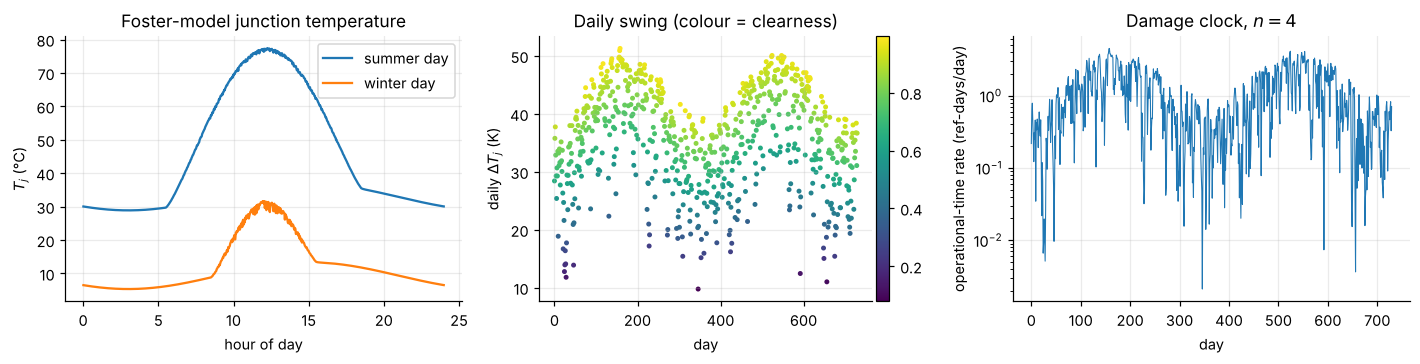

In [3]:
rng = np.random.default_rng(11)
w2 = make_weather(730, rng)
tmax2, dT2, trace = mission_stress(w2, 1.0, rng, keep=[172, 355])
a2, r2 = stress_features(tmax2, dT2)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
hrs = (np.arange(STEPS) + .5) * DT / 3600
ax[0].plot(hrs, trace[0], label="summer day"); ax[0].plot(hrs, trace[1], label="winter day")
ax[0].set(xlabel="hour of day", ylabel="$T_j$ (°C)", title="Foster-model junction temperature"); ax[0].legend()
sc = ax[1].scatter(np.arange(730), dT2, s=5, c=w2[2], cmap="viridis")
ax[1].set(xlabel="day", ylabel="daily $\\Delta T_j$ (K)", title="Daily swing (colour = clearness)")
fig.colorbar(sc, ax=ax[1], pad=0.01)
ax[2].semilogy(np.arange(730), a2 * r2 ** 4, lw=.7)
ax[2].set(xlabel="day", ylabel="operational-time rate (ref-days/day)", title="Damage clock, $n=4$")
plt.tight_layout(); plt.show()
sw = np.r_[0:60, 305:425, 670:730]; su = np.r_[120:240, 485:605]
print(f"mean clock rate (n=4): {np.mean(a2*r2**4):.2f} ref-days/day  |  "
      f"summer/winter ratio ~ {np.mean((a2*r2**4)[su])/np.mean((a2*r2**4)[sw]):.1f}x  |  "
      f"daily-rate spread (p5..p95): {np.percentile(a2*r2**4,5):.3f} .. {np.percentile(a2*r2**4,95):.2f}")

## 2 · A subordinator in operational time

Health indicator: the relative increase of $R_{DS(on)}$ in %, with an end-of-life criterion of **+20 %** (a common convention; used here only as an illustrative threshold). The latent damage is

$$D(\tau)=\underbrace{\Gamma\text{-process}(\mu,\alpha;\tau)}_{\text{gradual wear}}\;+\;\underbrace{\text{compound Poisson}(\lambda,\ \text{Exp}(m_J);\tau)}_{\text{rare step events, e.g. bond-wire heel cracks}},\qquad \tau=\tau(t)\ \text{from §1.}$$

Both parts are **non-decreasing Lévy processes**. Over an operational-time increment $s$ the gamma part is $\text{Gamma}(\text{shape}=\alpha s,\ \text{scale}=\mu/\alpha)$, so its mean rate is $\mu$ and its variance rate $\mu^2/\alpha$. The jump part is the integral of a **Poisson random measure** with intensity $\lambda s\,\nu(dx)$: the number of jumps is Poisson($\lambda s$) and the sum of $N$ exponential marks is Gamma($N$, $m_J$). Because increments of Lévy processes are independent, any run of days can be **aggregated exactly** into one draw, which is what makes the filter in §3 cheap. The next cell *tests* that claim rather than assuming it.

In [4]:
LAM_J, JUMP_MEAN, THRESH = 0.003, 0.35, 20.0      # jumps per ref-day, mean jump size [%], end-of-life [%]

def increments(mu, alpha, s, rng):
    """Increment of (gamma process + compound Poisson) over operational-time increment s (any shape)."""
    g = rng.gamma(alpha * s, mu / alpha)                              # gradual wear
    N = rng.poisson(LAM_J * s)                                        # number of jump events
    j = np.where(N > 0, rng.gamma(np.maximum(N, 1), JUMP_MEAN), 0.0)  # sum of N Exp marks = Gamma(N, m_J)
    return g + j

# --- test 1: exact aggregation of daily increments into one 10-day increment ---------------
rng = np.random.default_rng(1); mu_, al_ = 0.0045, 0.08
s_days = rng.uniform(0.3, 3.0, size=10); R_ = 40000
agg   = increments(mu_, al_, np.full(R_, s_days.sum()), rng)
daily = sum(increments(mu_, al_, np.full(R_, s), rng) for s in s_days)
ks = stats.ks_2samp(agg, daily)
print(f"aggregation test  : KS p-value = {ks.pvalue:.2f}  (aggregated mean {agg.mean():.4f} vs daily-sum mean {daily.mean():.4f})")

# --- test 2: Campbell / Lévy-Khintchine moments of the Poisson-random-measure jump part ----
s_ = 40.0
Nn = rng.poisson(LAM_J * s_, size=R_); jsum = np.where(Nn > 0, rng.gamma(np.maximum(Nn, 1), JUMP_MEAN), 0.0)
print(f"Campbell mean     : MC {jsum.mean():.4f}  vs  lambda*s*E[X]   = {LAM_J*s_*JUMP_MEAN:.4f}")
print(f"Campbell variance : MC {jsum.var():.4f}  vs  lambda*s*E[X^2] = {LAM_J*s_*2*JUMP_MEAN**2:.4f}")

# --- test 3: mean and variance of the full increment -----------------------------------------
x_ = increments(mu_, al_, np.full(R_, s_), rng)
print(f"full increment    : mean MC {x_.mean():.4f} vs {(mu_+LAM_J*JUMP_MEAN)*s_:.4f} | "
      f"var MC {x_.var():.4f} vs {(mu_**2/al_+LAM_J*2*JUMP_MEAN**2)*s_:.4f}")

aggregation test  : KS p-value = 0.18  (aggregated mean 0.0919 vs daily-sum mean 0.0935)
Campbell mean     : MC 0.0420  vs  lambda*s*E[X]   = 0.0420
Campbell variance : MC 0.0290  vs  lambda*s*E[X^2] = 0.0294
full increment    : mean MC 0.2228 vs 0.2220 | var MC 0.0389 vs 0.0395


demo device: fails at day 3070 (8.4 years); raw-indicator artefact RMS = 0.66 %  ->  after temperature compensation 0.33 %


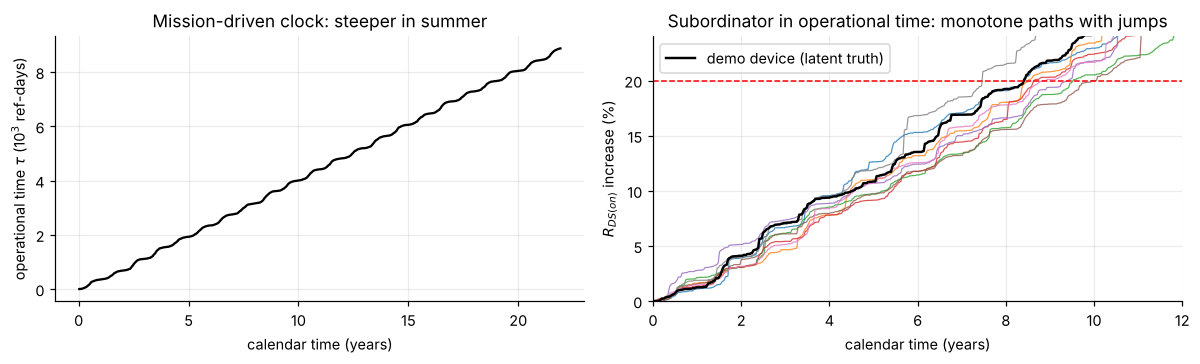

In [5]:
# --- a simulated device: mission -> clock -> latent damage -> noisy, temperature-contaminated measurements
SIG, C_T, SIG_TM, SIG_TS = 0.30, 0.20, 3.0, 0.5     # %, %/K, K, K
SIG_EFF = np.hypot(SIG, C_T * SIG_TS)               # residual noise after temperature compensation

def simulate_D(theta, A, R, rng, n_paths=1):
    """Latent damage on the characterisation grid; A, R: (M, H) daily stress features."""
    mu, alpha, n = theta
    s = (A * R ** n).sum(1)                                           # operational time per interval
    return np.cumsum(increments(mu, alpha, np.tile(s, (n_paths, 1)), rng), axis=1)

def make_device(theta, seed, n_days=8000, load=1.0):
    rng = np.random.default_rng(seed)
    w = make_weather(n_days, rng); tmax, dT, _ = mission_stress(w, load, rng)
    a, r = stress_features(tmax, dT)
    M = n_days // H; A = a[:M*H].reshape(M, H); R = r[:M*H].reshape(M, H)
    D = simulate_D(theta, A, R, rng)[0]
    j_f = int(np.argmax(D >= THRESH)) if (D >= THRESH).any() else None
    dTm = rng.normal(0, SIG_TM, M)                    # true case-temperature deviation at test
    dTs = dTm + rng.normal(0, SIG_TS, M)              # what the sensor reports
    y_raw = D + C_T * dTm + rng.normal(0, SIG, M)     # indicator contaminated by a reversible T-artefact
    return dict(theta=theta, A=A, R=R, D=D, j_f=j_f, y_raw=y_raw, y=y_raw - C_T * dTs)

THETA_DEMO = (0.0045, 0.08, 4.2)                       # (gamma mean rate [%/ref-day], shape rate, Coffin-Manson n)
dev = make_device(THETA_DEMO, seed=7)
print(f"demo device: fails at day {H*(dev['j_f']+1)} ({H*(dev['j_f']+1)/365:.1f} years); "
      f"raw-indicator artefact RMS = {np.std(dev['y_raw']-dev['D']):.2f} %  ->  after temperature compensation {np.std(dev['y']-dev['D']):.2f} %")

# sample paths in calendar time vs the operational-time clock
rng = np.random.default_rng(3)
paths = simulate_D(THETA_DEMO, dev["A"], dev["R"], rng, n_paths=8)
tau = np.cumsum((dev["A"] * dev["R"] ** THETA_DEMO[2]).sum(1))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
days = H * (np.arange(len(tau)) + 1) / 365
ax[0].plot(days, tau / 1000, c="k"); ax[0].set(xlabel="calendar time (years)", ylabel="operational time $\\tau$ (10$^3$ ref-days)",
        title="Mission-driven clock: steeper in summer"); 
for p in paths: ax[1].plot(days, p, lw=.8, alpha=.8)
ax[1].plot(days, dev["D"], "k", lw=1.6, label="demo device (latent truth)")
ax[1].axhline(THRESH, c="r", ls="--", lw=1); ax[1].set(xlim=(0, 12), ylim=(0, 24), xlabel="calendar time (years)", ylabel="$R_{DS(on)}$ increase (%)",
        title="Subordinator in operational time: monotone paths with jumps"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

## 3 · Sequential Monte Carlo with parameter learning

State: the latent damage $D_j$. Static unknowns: gradual-wear rate $\mu$, shape rate $\alpha$ (which sets process variability), and the Coffin–Manson exponent $n$ (which changes the *clock itself*, so each particle carries its own operational time). Every particle therefore re-evaluates $s_j=\sum_{k\in j}a_k r_k^{\,n}$ with its own $n$, propagates $D$ through the exact aggregated increment of §2, and is weighted by the Gaussian likelihood of the temperature-compensated indicator. Parameters are learned with the **Liu–West kernel shrinkage** at each resampling step (a standard, if approximate, device — §4 checks whether the approximation costs calibration).

Priors are deliberately broad (log-normal on $\mu,\alpha$; $n\sim\mathcal N(4,0.8^2)$). The jump parameters $(\lambda, m_J)$ are held at calibrated values in this demo; making them unknown is a straightforward extension but needs more data to identify.

SMC with 3000 particles over 306 characterisations: 0.2 s
  final posterior mu: mean 0.0048  (truth 0.0045)   [sd in log units: 0.090]
  final posterior alpha: mean 0.0749  (truth 0.08)   [sd in log units: 0.133]
  final posterior n : mean 3.7693  (truth 4.2)   [sd in units: 0.503]


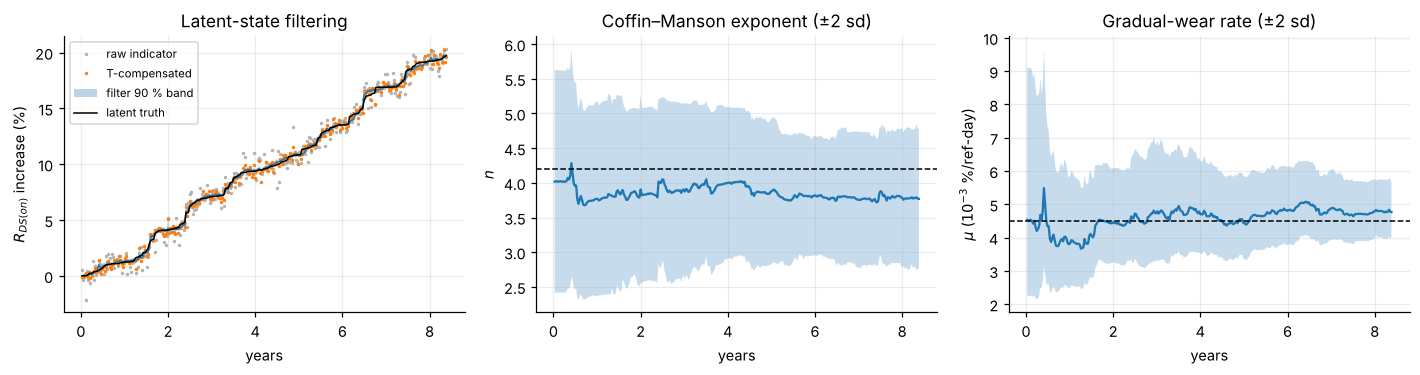

In [6]:
PRIOR = dict(logmu=(np.log(0.0045), 0.35), logalpha=(np.log(0.08), 0.5), n=(4.0, 0.8))

def sample_prior(size, rng):
    mu = np.exp(rng.normal(*PRIOR["logmu"], size)); al = np.exp(rng.normal(*PRIOR["logalpha"], size))
    n = np.clip(rng.normal(*PRIOR["n"], size), 1.5, 7.0)
    return mu, al, n

def systematic(w, rng):
    P = len(w); u = (rng.random() + np.arange(P)) / P
    return np.minimum(np.searchsorted(np.cumsum(w), u), P - 1)

def wquant(x, w, qs):
    o = np.argsort(x); cw = np.cumsum(w[o]); return x[o][np.minimum(np.searchsorted(cw, qs), len(x) - 1)]

def particle_filter(y, A, R, rng, P=1500, j_stop=None, a_lw=0.985, track=False,
                    snap_levels=(), snap_at=()):
    """SMC for the latent damage D with Liu-West learning of (log mu, log alpha, n).
    snap_levels: save particles the first time the filtered mean of D crosses each level (data-driven stopping).
    snap_at    : save particles at fixed interval indices."""
    M = len(y) if j_stop is None else j_stop
    mu, al, n = sample_prior(P, rng)
    th = np.vstack([np.log(mu), np.log(al), n]); D = np.zeros(P); w = np.full(P, 1.0 / P)
    hist = dict(mean=[], lo=[], hi=[], th_mean=[], th_sd=[]); snaps = {}; pending = list(snap_levels)
    for j in range(M):
        s = (A[j][None, :] * R[j][None, :] ** th[2][:, None]).sum(1)             # per-particle clock
        D = D + increments(np.exp(th[0]), np.exp(th[1]), s, rng)
        ll = -0.5 * ((y[j] - D) / SIG_EFF) ** 2
        w = w * np.exp(ll - ll.max()); w /= w.sum()
        mD = float(w @ D)
        if track:
            hist["mean"].append(mD); q = wquant(D, w, [.05, .95]); hist["lo"].append(q[0]); hist["hi"].append(q[1])
            m_ = th @ w; hist["th_mean"].append(m_.copy()); hist["th_sd"].append(np.sqrt(((th - m_[:, None]) ** 2) @ w))
        if j in snap_at or (pending and mD >= pending[0]):
            snaps[j if j in snap_at else pending.pop(0)] = (D.copy(), th.copy(), w.copy(), j)
        if 1.0 / np.sum(w ** 2) < 0.5 * P:                                       # resample + Liu-West move
            m_ = th @ w; C = ((th - m_[:, None]) * w) @ (th - m_[:, None]).T
            idx = systematic(w, rng); L = np.linalg.cholesky(C + 1e-12 * np.eye(3))
            th = a_lw * th[:, idx] + (1 - a_lw) * m_[:, None] + np.sqrt(1 - a_lw ** 2) * (L @ rng.normal(size=(3, P)))
            th[2] = np.clip(th[2], 1.0, 8.0); D = D[idx]; w = np.full(P, 1.0 / P)
        if snap_levels and not pending and not track: break                      # all checkpoints saved
    return hist, snaps

# --- run on the demo device, saving particles at 14 checkpoints --------------------------------
rng = np.random.default_rng(5)
j_f = dev["j_f"]; chk = np.unique(np.linspace(35, j_f - 6, 14).astype(int))
t0 = time.time()
hist, snaps = particle_filter(dev["y"], dev["A"], dev["R"], rng, P=3000, j_stop=j_f, track=True, snap_at=set(chk))
print(f"SMC with 3000 particles over {j_f} characterisations: {time.time()-t0:.1f} s")
for k, nm in enumerate(["mu", "alpha", "n "]):
    tm = np.array(hist["th_mean"])[:, k]; sd = np.array(hist["th_sd"])[:, k]
    tv = np.log(THETA_DEMO[k]) if k < 2 else THETA_DEMO[k]
    print(f"  final posterior {nm}: mean {tm[-1] if k==2 else np.exp(tm[-1]):.4f}  (truth {THETA_DEMO[k]})   "
          f"[sd in {'log ' if k<2 else ''}units: {sd[-1]:.3f}]")

tt = H * (np.arange(j_f) + 1) / 365
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(tt, dev["y_raw"][:j_f], ".", ms=2.5, c="0.7", label="raw indicator")
ax[0].plot(tt, dev["y"][:j_f], ".", ms=2.5, c="C1", label="T-compensated")
ax[0].fill_between(tt, hist["lo"], hist["hi"], alpha=.3, label="filter 90 % band"); ax[0].plot(tt, hist["mean"], lw=1)
ax[0].plot(tt, dev["D"][:j_f], "k", lw=1, label="latent truth"); ax[0].legend(fontsize=7.5, loc="upper left")
ax[0].set(xlabel="years", ylabel="$R_{DS(on)}$ increase (%)", title="Latent-state filtering")
thm = np.array(hist["th_mean"]); ths = np.array(hist["th_sd"])
ax[1].plot(tt, thm[:, 2]); ax[1].fill_between(tt, thm[:, 2] - 2 * ths[:, 2], thm[:, 2] + 2 * ths[:, 2], alpha=.25)
ax[1].axhline(THETA_DEMO[2], c="k", ls="--", lw=1); ax[1].set(xlabel="years", ylabel="$n$", title="Coffin–Manson exponent (±2 sd)")
ax[2].plot(tt, np.exp(thm[:, 0]) * 1e3); ax[2].fill_between(tt, np.exp(thm[:, 0] - 2 * ths[:, 0]) * 1e3, np.exp(thm[:, 0] + 2 * ths[:, 0]) * 1e3, alpha=.25)
ax[2].axhline(THETA_DEMO[0] * 1e3, c="k", ls="--", lw=1); ax[2].set(xlabel="years", ylabel="$\\mu$ ($10^{-3}$ %/ref-day)", title="Gradual-wear rate (±2 sd)")
plt.tight_layout(); plt.show()

## 4 · RUL distributions and whether they can be trusted

**Forecast.** From a checkpoint, each particle (conditioned on the device *still being alive*) is simulated forward through a **mission-profile climatology** — daily stress features resampled by day-of-year from a separate 25-year weather simulation — until its damage first crosses 20 %. The RUL distribution therefore carries three sources of uncertainty: parameter uncertainty, intrinsic process randomness (including the jumps), and future weather.

Below: a fan chart over the demo device's life; then a **simulation-based calibration** over many devices whose true parameters are drawn from the prior (so that, if the machinery is right, the randomised probability-integral transform of the true RUL must be uniform), against a naive baseline — linear regression of the indicator on calendar time with a slope-uncertainty error bar, i.e. "regression from a health indicator to a number".

true RUL inside the 90 % interval at 100 % of the 14 checkpoints (1.4 s)


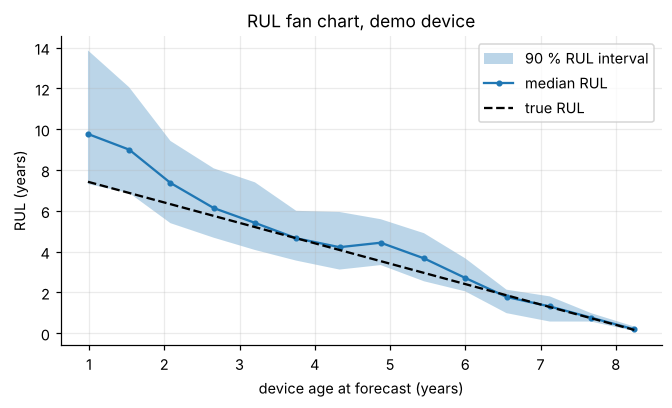

In [7]:
def build_library(load, years=25, seed=999):
    """Mission climatology: (365, years) arrays of daily stress features. Same seed => common random numbers across loads."""
    rng = np.random.default_rng(seed)
    w = make_weather(365 * years, rng); tmax, dT, _ = mission_stress(w, load, rng)
    a, r = stress_features(tmax, dT)
    return a.reshape(years, 365).T.copy(), r.reshape(years, 365).T.copy()

LIB = {1.0: build_library(1.0)}

def forecast_rul(snap, lib, rng, P=1500, max_days=9000):
    """Days until first passage of D over THRESH for each particle, conditioning on survival to the checkpoint."""
    D, th, w, j = snap
    w = w * (D < THRESH); w /= w.sum()
    idx = systematic(w, rng)[rng.permutation(len(w))[:P] if len(w) > P else slice(None)]
    D = D[idx].copy(); mu, al, n = np.exp(th[0][idx]), np.exp(th[1][idx]), th[2][idx]
    la, lr = lib; day0 = H * (j + 1); P = len(D)
    alive = np.ones(P, bool); t_fail = np.full(P, np.nan); step = 0
    while alive.any() and step * H < max_days:
        days = (day0 + step * H + np.arange(H)) % 365
        yrs = rng.integers(0, la.shape[1], size=(P, H))
        s = (la[days[None, :], yrs] * lr[days[None, :], yrs] ** n[:, None]).sum(1)
        D = np.where(alive, D + increments(mu, al, s, rng), D)
        newly = alive & (D >= THRESH); t_fail[newly] = (step + 1) * H
        alive &= ~newly; step += 1
    return t_fail

# --- fan chart over the demo device's life ---------------------------------------------------------
rng = np.random.default_rng(21); t0 = time.time()
fan = []
for j in sorted(snaps):
    f = forecast_rul(snaps[j], LIB[1.0], rng); f = f[~np.isnan(f)]
    fan.append((H * (j + 1) / 365, *np.percentile(f, [5, 50, 95]) / 365, (H * (j_f - j)) / 365))
fan = np.array(fan)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.fill_between(fan[:, 0], fan[:, 1], fan[:, 3], alpha=.3, label="90 % RUL interval"); ax.plot(fan[:, 0], fan[:, 2], "o-", ms=3, label="median RUL")
ax.plot(fan[:, 0], fan[:, 4], "k--", label="true RUL"); ax.set(xlabel="device age at forecast (years)", ylabel="RUL (years)", title="RUL fan chart, demo device")
ax.legend(); plt.tight_layout(); plt.show()
inside = np.mean((fan[:, 4] >= fan[:, 1]) & (fan[:, 4] <= fan[:, 3]))
print(f"true RUL inside the 90 % interval at {inside*100:.0f} % of the {len(fan)} checkpoints ({time.time()-t0:.1f} s)")

150 simulated devices (0 dropped: no failure within 27 years), 111 s

forecasts evaluated: 450 (per checkpoint level: 6% -> 150, 12% -> 150, 17% -> 150)

  central interval |   50% |   80% |   90% |   95%
SMC / subordinator |   49% |   79% |   87% |   93%
regression baseline |    7% |   12% |   13% |   17%

tail check, P(PIT<0.05) / P(PIT>0.95):  SMC 0.05 / 0.08   baseline 0.45 / 0.42   (ideal 0.05 / 0.05)
KS test for PIT uniformity: SMC p = 0.64, baseline p = 1.1e-73


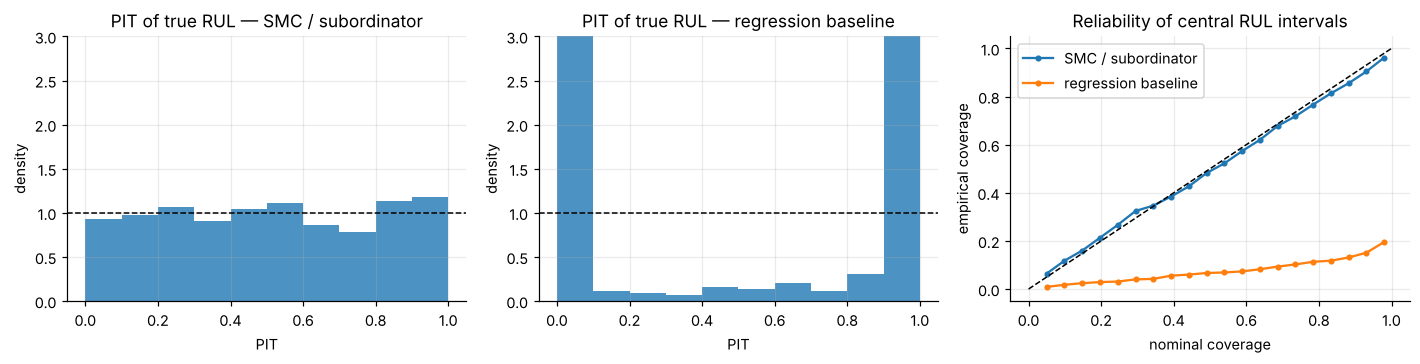

In [8]:
LEVELS = (6.0, 12.0, 17.0)      # data-driven checkpoints: first time the filtered mean damage crosses these levels [%]

def rand_pit(samples, truth, rng):
    """Randomised probability-integral transform of the true value under a (discrete or continuous) predictive sample."""
    s = np.where(np.isnan(samples), 1e9, samples)
    lo, hi = np.mean(s < truth), np.mean(s <= truth)
    return lo + rng.random() * (hi - lo)

def baseline_rul_samples(y, j_c, rng, n=2000):
    """Naive prognostic: OLS of the indicator on calendar time; RUL = (threshold - level)/slope, parameter uncertainty only."""
    t = H * (np.arange(j_c + 1) + 1.0); X = np.c_[np.ones_like(t), t]
    beta = np.linalg.lstsq(X, y[:j_c + 1], rcond=None)[0]; res = y[:j_c + 1] - X @ beta
    cov = (res @ res / (len(t) - 2)) * np.linalg.inv(X.T @ X)
    b = rng.multivariate_normal(beta, cov, size=n)
    rul = (THRESH - (b[:, 0] + b[:, 1] * t[-1])) / b[:, 1]
    return np.where((b[:, 1] > 0) & (rul > 0), rul, 1e9)

N_DEV = 150
rng = np.random.default_rng(2026); t0 = time.time()
U = {"smc": {l: [] for l in LEVELS}, "base": {l: [] for l in LEVELS}}; dropped = 0
for d in range(N_DEV):
    th_true = tuple(float(v[0]) for v in sample_prior(1, rng))                      # truth drawn from the prior
    dv = make_device(th_true, seed=1000 + d, n_days=10000)
    if dv["j_f"] is None: dropped += 1; continue
    _, sn = particle_filter(dv["y"], dv["A"], dv["R"], rng, P=1500, snap_levels=LEVELS)
    for lvl, snap in sn.items():
        j_c = snap[3]
        if j_c >= dv["j_f"]: continue                                                # already dead: nothing to forecast
        true_rul = H * (dv["j_f"] - j_c)
        U["smc"][lvl].append(rand_pit(forecast_rul(snap, LIB[1.0], rng, P=1000), true_rul, rng))
        U["base"][lvl].append(rand_pit(baseline_rul_samples(dv["y"], j_c, rng), true_rul, rng))
print(f"{N_DEV} simulated devices ({dropped} dropped: no failure within 27 years), {time.time()-t0:.0f} s")

def coverage(u, q): return np.mean(np.abs(np.asarray(u) - 0.5) <= q / 2)
pool = {k: np.concatenate([U[k][l] for l in LEVELS]) for k in U}
print(f"\nforecasts evaluated: {len(pool['smc'])} (per checkpoint level: " + ", ".join(f"{l:g}% -> {len(U['smc'][l])}" for l in LEVELS) + ")")
print(f"\n{'central interval':>18} | " + " | ".join(f"{q:>5.0%}" for q in (.5, .8, .9, .95)))
for k, nm in (("smc", "SMC / subordinator"), ("base", "regression baseline")):
    print(f"{nm:>18} | " + " | ".join(f"{coverage(pool[k], q):>5.0%}" for q in (.5, .8, .9, .95)))
print("\ntail check, P(PIT<0.05) / P(PIT>0.95):  SMC %.2f / %.2f   baseline %.2f / %.2f   (ideal 0.05 / 0.05)" %
      (np.mean(pool['smc'] < .05), np.mean(pool['smc'] > .95), np.mean(pool['base'] < .05), np.mean(pool['base'] > .95)))
print("KS test for PIT uniformity: SMC p = %.2f, baseline p = %.1e" % (stats.kstest(pool['smc'], 'uniform').pvalue, stats.kstest(pool['base'], 'uniform').pvalue))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a_, k, nm in ((ax[0], "smc", "SMC / subordinator"), (ax[1], "base", "regression baseline")):
    a_.hist(pool[k], bins=10, range=(0, 1), density=True, alpha=.8); a_.axhline(1, c="k", ls="--", lw=1)
    a_.set(title=f"PIT of true RUL — {nm}", xlabel="PIT", ylabel="density", ylim=(0, 3))
qs = np.linspace(.05, .98, 20)
for k, nm in (("smc", "SMC / subordinator"), ("base", "regression baseline")): ax[2].plot(qs, [coverage(pool[k], q) for q in qs], "o-", ms=3, label=nm)
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set(xlabel="nominal coverage", ylabel="empirical coverage", title="Reliability of central RUL intervals"); ax[2].legend()
plt.tight_layout(); plt.show()

**Reading the calibration result.** The SMC forecasts are close to calibrated (central-interval coverage within a few points of nominal), with a mild shortfall in the *upper* tail — the filter is a little too optimistic about very long remaining lives, which is the sort of effect Liu–West shrinkage and the independent-day climatology (which ignores weather persistence) would be expected to produce. The regression baseline is badly over-confident because its error bar only reflects slope uncertainty. Two caveats: the three checkpoints per device are correlated, so the pooled tests overstate the effective sample size (150 independent devices), and the model is well specified here by construction.

## 5 · Counterfactual mission-profile queries

Because the physics lives in the **clock**, a different mission profile only changes $\tau(t)$ — the posterior over the wear parameters is untouched. That makes "what if" questions cheap: keep the particles at today's checkpoint and forward-simulate them under a modified future load, using the *same* random numbers for every scenario (common random numbers) so differences are due to the intervention, not Monte-Carlo noise.

Two queries, taken from the project description, asked at the checkpoint where the posterior median RUL is closest to one year:
1. *What is the lifetime if the load is de-rated by 10 %?*
2. *Which load keeps the device alive to the next inspection (365 days) with probability 0.99?*

mission climatologies for 13 load levels built in 5 s
checkpoint at age 7.7 y (true RUL 0.74 y)
RUL, nominal load : median 0.78 y   90% interval [0.55, 0.99]
RUL, load x 0.90  : median 0.93 y   90% interval [0.66, 1.67]   -> median extension x1.2

P(alive at next inspection, 365 d) by load:  1.00:0.04  0.95:0.16  0.90:0.36  0.85:0.61  0.80:0.77  0.75:0.87  0.70:0.93  0.65:0.96  0.60:0.98  0.55:0.99  0.50:0.99  0.45:0.99  0.40:1.00
largest load meeting P(survive) >= 0.99 : ~0.50 of nominal  (de-rating of ~50 %)


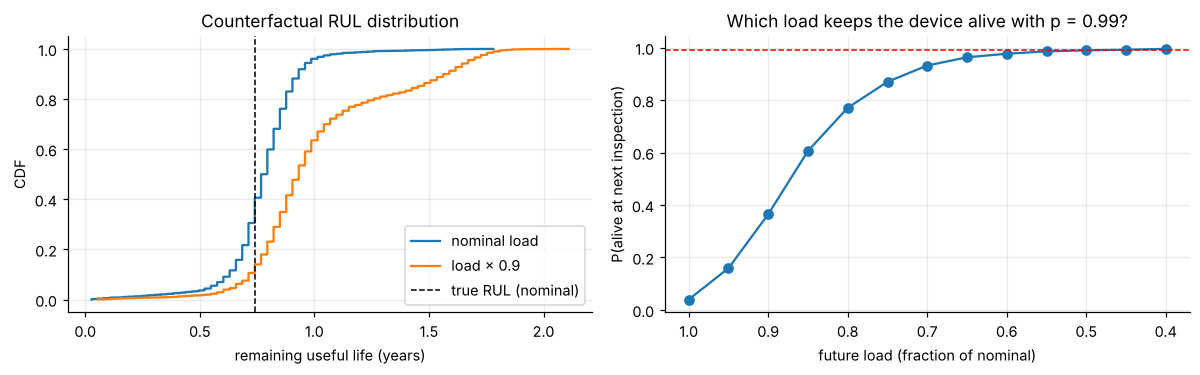

In [9]:
LOADS = [1.0, 0.95, 0.9, 0.85, 0.8, 0.75, 0.7, 0.65, 0.6, 0.55, 0.5, 0.45, 0.4]
t0 = time.time()
for L_ in LOADS:
    if L_ not in LIB: LIB[L_] = build_library(L_)                 # same weather seed => common random numbers
print(f"mission climatologies for {len(LOADS)} load levels built in {time.time()-t0:.0f} s")

jc = sorted(snaps)[int(np.argmin(np.abs(fan[:, 2] - 1.0)))]        # checkpoint chosen from the *forecast*, not the truth
snap = snaps[jc]
def rul_under(load, max_days=9000, P=3000):
    return forecast_rul(snap, LIB[load], np.random.default_rng(77), P=P, max_days=max_days)

nom, der = rul_under(1.0), rul_under(0.9)
q = lambda x: np.nanpercentile(x, [5, 50, 95]) / 365
print(f"checkpoint at age {H*(jc+1)/365:.1f} y (true RUL {H*(j_f-jc)/365:.2f} y)")
print(f"RUL, nominal load : median {q(nom)[1]:.2f} y   90% interval [{q(nom)[0]:.2f}, {q(nom)[2]:.2f}]")
print(f"RUL, load x 0.90  : median {q(der)[1]:.2f} y   90% interval [{q(der)[0]:.2f}, {q(der)[2]:.2f}]   "
      f"-> median extension x{np.nanmedian(der)/np.nanmedian(nom):.1f}")

surv = np.array([np.mean(~(rul_under(L_, max_days=370) <= 365)) for L_ in LOADS])
ok = np.where(surv >= 0.99)[0]
L99 = np.interp(0.99, np.maximum.accumulate(surv), LOADS) if surv.max() >= 0.99 else np.nan   # surv rises as load falls
print("\nP(alive at next inspection, 365 d) by load:  " + "  ".join(f"{L_:.2f}:{s_:.2f}" for L_, s_ in zip(LOADS, surv)))
print(f"largest load meeting P(survive) >= 0.99 : ~{L99:.2f} of nominal  (de-rating of ~{(1-L99)*100:.0f} %)" if np.isfinite(L99) else "no load on the grid reaches 0.99")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for x_, nm in ((nom, "nominal load"), (der, "load × 0.9")):
    xs = np.sort(x_[~np.isnan(x_)]) / 365; ax[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=nm)
ax[0].axvline(H * (j_f - jc) / 365, c="k", ls="--", lw=1, label="true RUL (nominal)")
ax[0].set(xlabel="remaining useful life (years)", ylabel="CDF", title="Counterfactual RUL distribution"); ax[0].legend()
ax[1].plot(LOADS, surv, "o-"); ax[1].axhline(.99, c="r", ls="--", lw=1)
ax[1].set(xlabel="future load (fraction of nominal)", ylabel="P(alive at next inspection)", title="Which load keeps the device alive with p = 0.99?")
ax[1].invert_xaxis(); plt.tight_layout(); plt.show()

## 6 · Experimental design: which accelerated-ageing campaigns identify the exponent?

The project's premise is that the data should be produced *around the requirements of the model*. A quick, quantitative instance: if all test devices are cycled at a **single** $\Delta T$, the model can only identify the product $\mu\,r^{n}$, never $\mu$ and $n$ separately; spreading the same total test time over **several** levels breaks that degeneracy. Both designs below use 12 devices × 60 increments × 14 days; increments are assumed to be read with lab-grade (negligible) noise, which is a simplification — the noisy case needs the machinery of §3. Maximum-likelihood fits use the exact gamma-increment likelihood.

A: one level (12 dev. at 1.2 x 36 K)                   : n-hat median 4.69, sd 1.18, RMSE 1.34
B: three levels (4 dev. each at 0.8/1.2/1.6 x 36 K)    : n-hat median 4.21, sd 0.09, RMSE 0.09
(design A: the likelihood is flat along a ridge where only mu*r^n is pinned down, so n-hat just reflects the optimiser's start)

total notebook runtime: 121 s


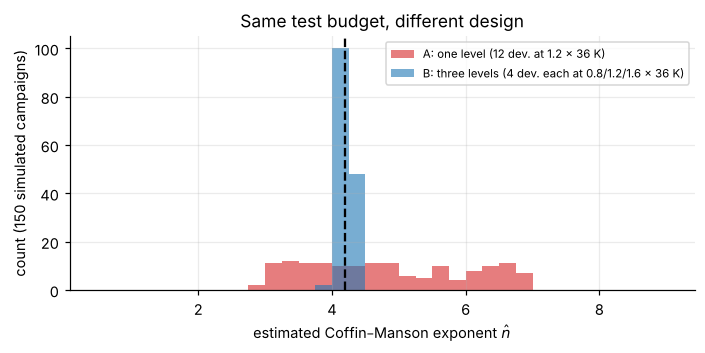

In [10]:
def lab_nll(th, r_lv, d, dt):
    mu, al, n = np.exp(th[0]), np.exp(th[1]), th[2]
    k = al * r_lv ** n * dt; sc = mu / al                         # controlled-temperature lab test: a_k = 1
    return -np.sum((k - 1) * np.log(d) - d / sc - k * np.log(sc) - special.gammaln(k))

def run_design(levels_r, reps, rng, truth=THETA_DEMO, n_inc=60, dt=14.0):
    """MLE of n over repeated simulated campaigns; random optimiser starts so a flat likelihood ridge shows up as spread."""
    r_lv = np.repeat(levels_r, n_inc)
    est = []
    for _ in range(reps):
        d = rng.gamma(truth[1] * r_lv ** truth[2] * dt, truth[0] / truth[1])
        fit = optimize.minimize(lab_nll, x0=[np.log(0.003), np.log(0.05), rng.uniform(1.5, 7.0)], args=(r_lv, d, dt), method="L-BFGS-B",
                                bounds=[(-9, -3), (-5, 3), (0.5, 9)])
        est.append(fit.x[2])
    return np.array(est)

rng = np.random.default_rng(8)
designs = {"A: one level (12 dev. at 1.2 x 36 K)": np.full(12, 1.2),
           "B: three levels (4 dev. each at 0.8/1.2/1.6 x 36 K)": np.repeat([0.8, 1.2, 1.6], 4)}
res = {k: run_design(v, 150, rng) for k, v in designs.items()}
fig, ax = plt.subplots(figsize=(6.5, 3.3))
for (k, e), c in zip(res.items(), ("C3", "C0")):
    ax.hist(e, bins=np.linspace(0.5, 9, 35), alpha=.6, color=c, label=k)
    print(f"{k:55s}: n-hat median {np.median(e):.2f}, sd {np.std(e):.2f}, RMSE {np.sqrt(np.mean((e-THETA_DEMO[2])**2)):.2f}")
print("(design A: the likelihood is flat along a ridge where only mu*r^n is pinned down, so n-hat just reflects the optimiser's start)")
ax.axvline(THETA_DEMO[2], c="k", ls="--"); ax.set(xlabel="estimated Coffin–Manson exponent $\\hat n$", ylabel="count (150 simulated campaigns)",
       title="Same test budget, different design"); ax.legend(fontsize=7.5); plt.tight_layout(); plt.show()
print(f"\ntotal notebook runtime: {time.time()-T_START:.0f} s")

## 7 · What this does and does not show — and what the real project would change

**Shows.** (i) Device physics can enter a prognostic model as an *operational-time clock* through a Foster thermal model, leaving a physically interpretable subordinator for the latent state; (ii) SMC with parameter learning gives full RUL *distributions* whose central intervals are close to calibrated in simulation-based testing, where a regression-on-calendar-time baseline is not; (iii) conditional and counterfactual mission-profile questions are cheap once the clock is explicit; (iv) the same model tells an experimentalist which stress levels to test.

**Does not show.** No real SiC data were used and the model is well specified by construction; the thermal network, $E_a$ and the end-of-life criterion are illustrative. The daily $(T_{j,\max},\Delta T_j)$ summary stands in for proper rainflow cycle counting; the jump parameters are fixed rather than learned; semiconductor-level and package-level mechanisms are folded into one latent indicator; the Liu–West filter is an approximation (visible as a mild upper-tail optimism); and the baseline is deliberately simple. 

**Natural next steps** (the content of DC5): joint inference of jump and gamma parameters with SMC² or variational inference; separate subordinators per failure mechanism, with indicators chosen to separate wear-out from reversible trapping/temperature artefacts; rainflow-resolved clocks from measured mission profiles; ageing laws calibrated on real accelerated-ageing campaigns (with designs like §6); and benchmarking against stronger baselines (calendar-time gamma processes, deep-ensemble/MC-dropout RUL networks) on an open multi-physics SiC dataset.